# Backtest 3 · Hourly walk-forward (Vantage spreads)

TRAIN 2019 – 2022: try 36 parameter combinations, keep crosses that made money before costs, pick the best after-cost Sharpe. TEST 2023 → latest: run that single choice untouched.

In [1]:
import sys
sys.path.insert(0, "../src")   # shared code lives in src/; data in ../data (see README)
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

In [2]:
%run ../src/walk_forward.py

  (480, 1.5, 0.0, 24.0): train Sharpe  0.30 | test Sharpe -0.41


  (480, 1.5, 0.0, 48.0): train Sharpe  0.53 | test Sharpe -0.68


  (480, 1.5, 0.0, 96.0): train Sharpe  0.38 | test Sharpe -1.04


  (480, 1.5, 0.5, 24.0): train Sharpe  0.20 | test Sharpe -0.49


  (480, 1.5, 0.5, 48.0): train Sharpe  0.42 | test Sharpe -0.66


  (480, 1.5, 0.5, 96.0): train Sharpe  0.36 | test Sharpe -1.19


... (30 outputs left out)


Top 10 by TRAIN Sharpe (the test columns are shown for transparency, not used to choose):
 window  entry  exit  max_hl  crosses  train trades  TRAIN Sharpe  TRAIN %/yr  test Sharpe  test %/yr
    480    2.5   0.0    96.0        6          1477          0.53        3.19        -0.83      -5.24
    480    1.5   0.0    48.0        7          3876          0.53        4.76        -0.68      -5.79
    960    1.5   0.5    48.0        7          1459          0.53        2.65        -0.58      -2.70
    480    2.5   0.0    48.0        6          1334          0.46        2.50        -0.42      -2.20
    960    2.0   0.0    48.0        5           559          0.46        1.85         0.09       0.31
    960    2.0   0.0    96.0        6          1205          0.43        2.71        -0.44      -2.72
    480    1.5   0.5    48.0        7          4553          0.42        3.31        -0.66      -4.99
    960    2.5   0.0    96.0        5           516          0.42        1.79        -0.72   

    risk x1: 172 attempts | unfinished 89% | fail: max loss 11%


    risk x2: 176 attempts | unfinished 43% | fail: max loss 27% | pass 19% | fail: daily loss 11%


    risk x4: 193 attempts | pass 46% | fail: max loss 29% | fail: daily loss 24% | unfinished 1%

Robustness: how all 36 combinations did in TEST
  positive test Sharpe: 7 of 36   median test Sharpe -0.46   corr(train Sharpe, test Sharpe) -0.28


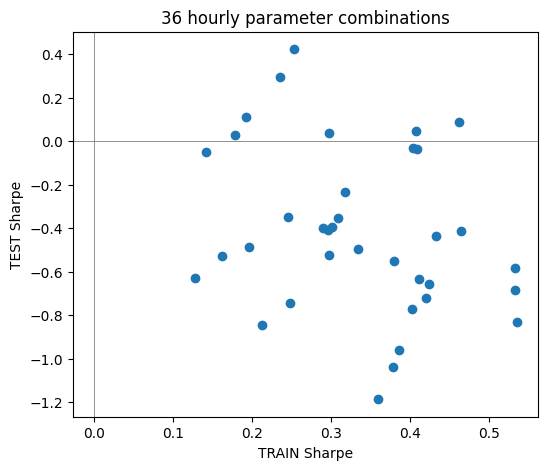

In [3]:
g = pd.read_csv("../data/backtest_fx/walk_forward_grid.csv")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(g["TRAIN Sharpe"], g["test Sharpe"])
ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel("TRAIN Sharpe"); ax.set_ylabel("TEST Sharpe")
ax.set_title("36 hourly parameter combinations")
plt.show()

**Result:** the chosen hourly setup is about flat in the test period; only a few of the 36 combinations are positive. Hourly is not tradable after costs.